# Bitcoin Illicit Transaction Detection - Final Model

The data has 49 time steps. Steps 1-35 are the training set (each transaction is labelled licit, illicit or unknown) and steps 36-49 are the test set. Submissions are scored with ROC-AUC over all test transactions.

Prior research on Bitcoin transaction data show that Illicit activity on Bitcoin can change abruptly, for example when a darknet marketplace is shut down, and a model trained on earlier periods will keep scoring transactions that resemble the old activity as suspicious (https://link.springer.com/article/10.1038/s41598-020-74416-y). I therefore checked whether my model's predictions change sharply partway through the test steps. Section 6 finds this change point from the test data and the model's scores, confirms it on the public leaderboard, and only adjusts predictions after it.

My approach:
1. A quick look at the transaction graph: do illicit transactions cluster together, and are centrality measures useful?
2. Creation of neighbour difference model a LightGBM on time-stable features plus "edge-difference" features, i.e. how different a transaction is from the ones it sends to and receives from.
3. A post-shutdown adjustment. After the change point found in the test data, I lower the scores of connected transactions that look like the large illicit campaign from steps 24-32.
4. Writing the submission file (Section 7) and comparing the model with baselines on three time-based validation windows (Section 8).

The results are discussed in my report.

## 1. Setup

Train.csv, test.csv and txs_edgelist.csv in a folder data are expected to be found, put it there before running

### Importing Libraries

In [185]:
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
import lightgbm as lgb
from scipy import sparse, stats
from scipy.sparse.csgraph import connected_components
from sklearn.metrics import roc_auc_score
from IPython.display import display

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)

### Reading Files

In [186]:
df_train = pd.read_csv("data/train.csv", dtype={"txId": str})
df_test = pd.read_csv("data/test.csv", dtype={"txId": str})
df_edges = pd.read_csv("data/txs_edgelist.csv", dtype={"txId1": str, "txId2": str}).dropna()

print("train:", df_train.shape)
print("test: ", df_test.shape)
print("edges:", df_edges.shape)

train: (141772, 168)
test:  (15329, 168)
edges: (234355, 2)


In [187]:
display(df_train.head())

,txId,time_step,feat_1,feat_2,feat_3,feat_4,feat_5,feat_6,feat_7,feat_8,feat_9,feat_10,feat_11,feat_12,feat_13,feat_14,feat_15,feat_16,feat_17,feat_18,feat_19,feat_20,feat_21,feat_22,feat_23,feat_24,feat_25,feat_26,feat_27,feat_28,...,feat_137,feat_138,feat_139,feat_140,feat_141,feat_142,feat_143,feat_144,feat_145,feat_146,feat_147,feat_148,feat_149,feat_150,feat_151,feat_152,feat_153,feat_154,feat_155,feat_156,feat_157,feat_158,feat_159,feat_160,feat_161,feat_162,feat_163,feat_164,feat_165,label
0,230425980,1,-0.171469,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.162097,-0.167933,-0.049707,-0.164402,-0.028741,-0.035391,-0.042955,-0.013282,-0.057195,-0.169609,-0.171154,-0.174473,-1.373657,-1.371460,-0.139731,-0.148912,-0.080147,-0.155661,-0.010763,-0.012107,-0.139733,...,-1.354735,-0.297975,-1.403698,1.342003,1.340733,-0.171601,-0.458162,-0.423588,-0.440883,-1.015963,-1.016230,-0.968903,-0.375715,0.759748,-0.768329,1.488113,1.487932,-0.216814,-0.605631,-0.562153,-0.600999,1.461330,1.461369,0.018279,-0.087490,-0.131155,-0.097524,-0.120613,-0.119792,NaN
1,5530458,1,-0.171484,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.162112,-0.167948,-0.049707,-0.164417,-0.028741,-0.035391,-0.042955,-0.013282,-0.055327,-0.169757,-0.171477,-0.174490,0.887058,0.884557,-0.139731,-0.148912,-0.080147,-0.155661,-0.010763,-0.012107,-0.139733,...,-1.353918,-0.295982,-1.403215,-0.975738,-0.975237,-0.168742,-0.263290,-0.186389,-0.250875,-1.015963,-1.016230,-0.968903,0.146997,1.366287,-0.464773,-1.116918,-1.116948,-0.216814,0.634272,0.947382,0.673103,-0.979074,-0.978556,0.018279,-0.087490,-0.131155,-0.097524,-0.120613,-0.119792,NaN
2,232022460,1,-0.172107,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.162749,-0.168576,-0.049707,-0.165054,-0.028741,-0.035391,-0.042955,-0.013282,-0.055298,-0.170400,-0.172217,-0.175227,0.887058,0.884557,-0.139729,-0.148911,-0.080147,-0.155660,-0.010763,-0.012107,-0.139731,...,-1.356210,-0.301548,-1.404577,-0.975738,-0.975237,-0.168742,-0.192468,-0.099790,-0.182133,-1.015963,-1.016230,-0.968903,-1.421138,-0.453330,-1.375441,-1.116918,-1.116948,-0.216814,0.407161,0.670883,0.439728,-0.979074,-0.978556,-0.098889,-0.106715,-0.131155,-0.183671,-0.120613,-0.119792,NaN
3,232438397,1,0.163054,1.963790,-0.646376,12.409294,-0.063725,9.782742,12.414558,-0.163645,-0.115831,0.043598,-0.163905,1.059993,2.397457,-0.063200,-0.013282,4.800240,0.174329,-0.172908,0.619399,-0.243300,-0.243452,-0.139732,-0.146895,-0.079667,-0.155554,0.773847,0.378516,-0.139734,...,-1.356131,-0.301754,-1.404445,0.183133,0.182748,-0.163577,-0.456561,-0.424672,-0.436915,0.143001,0.142525,-0.425896,-1.421138,-1.059868,-1.071885,0.185597,0.185492,-0.216814,-0.617907,-0.577099,-0.613614,0.241128,0.241406,1.072793,0.085530,-0.131155,0.677799,-0.120613,-0.119792,0.0
4,230460314,1,1.011523,-0.081127,-1.201369,1.153668,0.333276,1.312656,-0.061584,-0.163523,0.041399,0.935886,-0.098695,1.203038,0.988902,0.341693,-0.013282,-0.057392,0.058329,-0.032930,-0.042709,0.065455,0.324947,-0.139732,-0.148854,-0.080105,-0.155638,1.313051,1.106965,-0.139734,...,-1.355393,-0.300941,-1.404583,0.064846,-0.035232,-0.168742,-0.442156,-0.416540,-0.418273,0.367605,0.392035,-0.968903,-1.943850,-1.059868,-1.678997,0.185597,0.185492,-0.169472,-0.470592,-0.511871,-0.400422,0.517257,0.579382,0.018279,0.277775,0.326394,1.293750,0.178136,0.179117,NaN


### Cleaning and building arrays

I stack train and test into one set of arrays so the graph features only need to be computed once. The label is 1 for illicit, 0 for licit and NaN for unknown and test transactions.

In [188]:
feature_cols = sorted([c for c in df_train.columns if c.startswith("feat_")], key=lambda c: int(c.split("_")[-1]))

for df in (df_train, df_test):
    df["txId"] = df["txId"].str.strip()
    df[feature_cols] = (df[feature_cols].apply(pd.to_numeric, errors="coerce")
                        .astype("float32").replace([np.inf, -np.inf], np.nan))

df_train["label"] = pd.to_numeric(df_train["label"], errors="coerce")
df_train.loc[~df_train["label"].isin([0, 1]), "label"] = np.nan

X_ALL = np.vstack([df_train[feature_cols].to_numpy(np.float32), df_test[feature_cols].to_numpy(np.float32)])
STEP = np.r_[df_train["time_step"].to_numpy(), df_test["time_step"].to_numpy()]
LABEL = np.r_[df_train["label"].to_numpy(float), np.full(len(df_test), np.nan)]
TXID = np.r_[df_train["txId"].to_numpy(), df_test["txId"].to_numpy()]
IS_TEST = np.r_[np.zeros(len(df_train), bool), np.ones(len(df_test), bool)]

LABELLED = np.flatnonzero(np.isfinite(LABEL))
TEST_IDX = np.flatnonzero(IS_TEST)
OBSERVED = np.isfinite(LABEL) | IS_TEST    
N = len(STEP)

print(f"Transactions: {N:,} (labelled {len(LABELLED):,}, unlabelled {int((~OBSERVED).sum()):,}, test {len(TEST_IDX):,})")
print(f"Illicit share among labelled: {np.nanmean(LABEL):.3f}")
print(f"Features: {len(feature_cols)}")

Transactions: 157,101 (labelled 31,235, unlabelled 110,537, test 15,329)
Illicit share among labelled: 0.117
Features: 165


### Building the edge list

Each edge is a payment from one transaction to another, and edges only connect transactions in the same time step. I build two versions:
- the full graph with all transactions, used for the graph study
- a "test-like" graph with only the labelled training transactions and the test transactions. The test steps have no unknown transactions, so the model features are built from this graph so that train and test look the same.

In [189]:
ids = pd.Index(TXID)
src_all = ids.get_indexer(df_edges["txId1"].str.strip())
dst_all = ids.get_indexer(df_edges["txId2"].str.strip())
valid = (src_all >= 0) & (dst_all >= 0) & (src_all != dst_all)
valid &= STEP[np.maximum(src_all, 0)] == STEP[np.maximum(dst_all, 0)]
src_all, dst_all = src_all[valid], dst_all[valid]

# test-like graph
keep = OBSERVED[src_all] & OBSERVED[dst_all]
src, dst = sparse.csr_matrix((np.ones(keep.sum(), np.float32), (src_all[keep], dst_all[keep])), shape=(N, N)).nonzero()

IN_DEG = np.bincount(dst, minlength=N)
OUT_DEG = np.bincount(src, minlength=N)
CONNECTED = (IN_DEG + OUT_DEG) > 0

UND = sparse.csr_matrix((np.ones(2 * len(src)), (np.r_[src, dst], np.r_[dst, src])), shape=(N, N))
UND.data[:] = 1.0
UND = UND.tocsr()

print(f"Full graph edges:      {len(src_all):,}")
print(f"Test-like graph edges: {len(src):,}")

Full graph edges:      175,918
Test-like graph edges: 36,624


## 2. Graph Study

Before building features I check two things on the full graph:
1. Homophily: are illicit transactions linked to other illicit transactions more often than by chance?
2. Centrality: do degree or PageRank separate illicit from licit transactions?

### Graph overview per time step

step,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,42,43,44,45,46,47,48,49
nodes,7880.000,4544.000,6621.000,5693.000,6803.000,4328.00,6048.000,4457.000,4996.000,6727.000,4296.000,2047.000,4528.00,2022.000,3639.000,2975.000,3385.000,1976.000,3506.000,4291.000,3537.000,5894.00,4165.000,4592.000,2314.000,2523.000,1089.000,1653.000,4275.00,2483.000,2816.000,4525.000,3151.000,2486.000,5507.000,1708.000,498.000,756.000,1183.000,1211.000,1132.000,2154.000,1370.000,1591.000,1221.000,712.000,846.000,471.000,476.000
edges,9164.000,5241.000,8316.000,8180.000,8623.000,5242.00,7253.000,5186.000,5939.000,8588.000,4656.000,2213.000,4827.00,2078.000,3823.000,3120.000,3650.000,2115.000,3838.000,4755.000,3959.000,7014.00,4584.000,5124.000,2619.000,2690.000,1168.000,1717.000,4541.00,2561.000,3049.000,4952.000,3366.000,2692.000,6351.000,1148.000,423.000,653.000,1055.000,1180.000,1048.000,1443.000,935.000,1497.000,1346.000,388.000,822.000,371.000,415.000
largest component share,1.000,1.000,1.000,1.000,1.000,1.00,1.000,1.000,1.000,1.000,1.000,1.000,1.00,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.00,1.000,1.000,1.000,1.000,1.000,1.000,1.00,1.000,1.000,1.000,1.000,1.000,1.000,0.491,0.683,0.642,0.681,0.694,0.629,0.436,0.494,0.552,0.771,0.383,0.722,0.671,0.683
illicit share (labelled),0.008,0.016,0.009,0.021,0.004,0.01,0.085,0.058,0.319,0.019,0.188,0.032,0.36,0.103,0.238,0.242,0.122,0.134,0.107,0.289,0.156,0.09,0.045,0.122,0.199,0.186,0.117,0.299,0.28,0.158,0.149,0.259,0.052,0.072,0.136,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


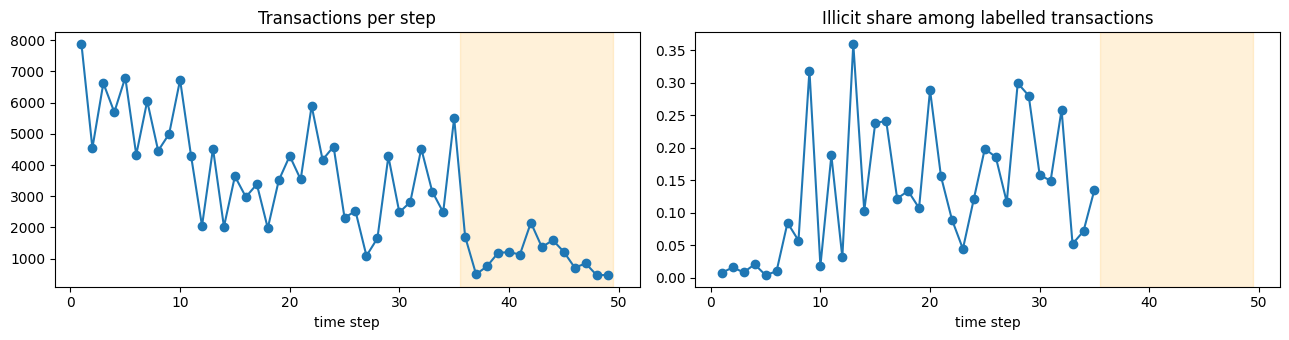

In [190]:
G = nx.DiGraph()
G.add_nodes_from(range(N))
G.add_edges_from(zip(src_all.tolist(), dst_all.tolist()))

overview = []
for t in np.unique(STEP):
    nodes_t = np.flatnonzero(STEP == t)
    sub = G.subgraph(nodes_t.tolist())
    largest = max(len(c) for c in nx.weakly_connected_components(sub))
    overview.append({"step": t, "nodes": sub.number_of_nodes(), "edges": sub.number_of_edges(),
                     "largest component share": largest / len(nodes_t),
                     "illicit share (labelled)": np.nanmean(LABEL[nodes_t]) if np.isfinite(LABEL[nodes_t]).any() else np.nan})
overview = pd.DataFrame(overview).set_index("step")
display(overview.T.round(3))

fig, ax = plt.subplots(1, 2, figsize=(13, 3.5))
overview["nodes"].plot(ax=ax[0], marker="o", title="Transactions per step")
overview["illicit share (labelled)"].plot(ax=ax[1], marker="o", title="Illicit share among labelled transactions")
for a in ax:
    a.axvspan(35.5, STEP.max() + 0.5, color="orange", alpha=0.15)
    a.set_xlabel("time step")
plt.tight_layout()
plt.show()

### Homophily

Edge homophily is the share of edges (between two labelled transactions) where both transactions have the same class. As a baseline I shuffle the labels within each step 100 times.

In [191]:
lab_edges = np.isfinite(LABEL[src_all]) & np.isfinite(LABEL[dst_all])
eu, ev = src_all[lab_edges], dst_all[lab_edges]
observed = (LABEL[eu] == LABEL[ev]).mean()

rng = np.random.default_rng(42)
shuffled = []
for _ in range(100):
    lab_s = LABEL.copy()
    for t in np.unique(STEP[LABELLED]):
        idx = LABELLED[STEP[LABELLED] == t]
        lab_s[idx] = rng.permutation(lab_s[idx])
    shuffled.append((lab_s[eu] == lab_s[ev]).mean())

ill_edges = (LABEL[eu] == 1) | (LABEL[ev] == 1)
print(f"Labelled-labelled edges:        {len(eu):,}")
print(f"Edge homophily (observed):      {observed:.3f}")
print(f"Edge homophily (shuffled mean): {np.mean(shuffled):.3f}  (97.5th percentile {np.percentile(shuffled, 97.5):.3f})")
print(f"Edges touching an illicit transaction that join two illicit ones: {((LABEL[eu] == 1) & (LABEL[ev] == 1))[ill_edges].mean():.3f}")

Labelled-labelled edges:        23,900
Edge homophily (observed):      0.947
Edge homophily (shuffled mean): 0.820  (97.5th percentile 0.827)
Edges touching an illicit transaction that join two illicit ones: 0.403


### Centrality

Each measure is computed on the full graph and scored with ROC-AUC on the labelled transactions (0.5 = no signal, below 0.5 = the measure is lower for illicit transactions).

,ROC-AUC
PageRank (reverse),0.383
out-degree,0.417
in-degree,0.458
PageRank (forward),0.495


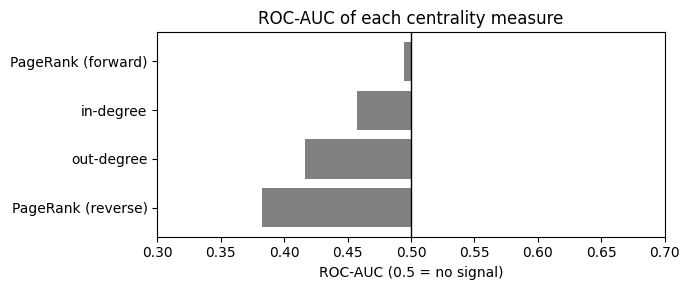

In [192]:
pr_forward = nx.pagerank(G, alpha=0.85)
pr_reverse = nx.pagerank(G.reverse(copy=False), alpha=0.85)

centrality = pd.DataFrame({
    "in-degree": np.array([G.in_degree(i) for i in range(N)]),
    "out-degree": np.array([G.out_degree(i) for i in range(N)]),
    "PageRank (forward)": np.array([pr_forward[i] for i in range(N)]),
    "PageRank (reverse)": np.array([pr_reverse[i] for i in range(N)]),
})

y_lab = LABEL[LABELLED].astype(int)
cent_auc = pd.Series({m: roc_auc_score(y_lab, centrality[m].to_numpy()[LABELLED]) for m in centrality.columns},
                     name="ROC-AUC").sort_values()
display(cent_auc.round(3).to_frame())

fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(cent_auc.index, cent_auc.values - 0.5, left=0.5, color="grey")
ax.axvline(0.5, color="black", lw=1)
ax.set_xlim(0.3, 0.7)
ax.set_xlabel("ROC-AUC (0.5 = no signal)")
ax.set_title("ROC-AUC of each centrality measure")
plt.tight_layout()
plt.show()

## 3. Feature Engineering

### Stable feature selection

Some features are related to the label in one direction in some steps and the opposite direction in others, which hurts on future steps. For each feature I compute its ROC-AUC inside every training step and only keep it if it points the same way (above or below 0.5) in at least 80% of the steps where it has a clear direction (AUC outside 0.5 ± 0.02).

In [193]:
_stable_cache = {}


def stable_features(X, train_rows, name, target=None, margin=0.02, min_share=0.8):
    y_all = LABEL if target is None else target
    key = (name, len(train_rows), int(train_rows[0]), int(train_rows[-1]), target is None)
    if key not in _stable_cache:
        step_aucs = []
        for t in np.unique(STEP[train_rows]):
            rows = train_rows[STEP[train_rows] == t]
            y = y_all[rows].astype(int)
            if len(np.unique(y)) < 2:
                continue
            Xt = X[rows].astype(np.float64)
            med = np.nanmedian(Xt, axis=0)
            Xt = np.where(np.isfinite(Xt), Xt, np.where(np.isfinite(med), med, 0))
            step_aucs.append([roc_auc_score(y, Xt[:, j]) if np.std(Xt[:, j]) > 0 else 0.5 for j in range(X.shape[1])])
        _stable_cache[key] = np.array(step_aucs) if step_aucs else np.full((1, X.shape[1]), 0.5)
    aucs = _stable_cache[key]
    votes = np.where(aucs > 0.5 + margin, 1, np.where(aucs < 0.5 - margin, -1, 0))
    up, down = (votes == 1).sum(0), (votes == -1).sum(0)
    share = np.divide(np.maximum(up, down), up + down, out=np.zeros(X.shape[1]), where=(up + down) > 0)
    return np.flatnonzero(share >= min_share)


kept = stable_features(X_ALL, LABELLED, "raw")
print(f"Stable raw features (all training steps): {len(kept)} of {X_ALL.shape[1]}")

Stable raw features (all training steps): 96 of 165


### Edge-difference features

For each of the 165 features I take the mean absolute difference between a transaction and
- its predecessors (transactions that pay into it)
- its successors (transactions it pays into)

This gives 330 columns, and the stable feature selection above decides which of them the model uses. If a transaction has no neighbours on one side the value is NaN, which LightGBM can handle. I use the test-like graph here so the features are built the same way for train and test.

In [194]:
X_FILLED = np.nan_to_num(X_ALL.astype(np.float32))


def edge_difference_features(cols):
    X = X_FILLED[:, cols]
    diff = np.abs(X[dst] - X[src])
    blocks = []
    for node in (dst, src): 
        count = np.bincount(node, minlength=N).astype(np.float64)
        total = np.zeros((N, len(cols)))
        np.add.at(total, node, diff)
        mean = total / np.maximum(count, 1)[:, None]
        mean[count == 0] = np.nan
        blocks.append(mean)
    out = np.hstack(blocks).astype(np.float32)
    out[~OBSERVED] = np.nan
    return out


EDGE_DIFF = edge_difference_features(np.arange(X_ALL.shape[1]))  # all features, no local/aggregated split
print("Edge-difference block:", EDGE_DIFF.shape)
print(f"Labelled transactions with at least one predecessor: {np.isfinite(EDGE_DIFF[LABELLED, 0]).mean():.1%}")
print(f"Test transactions with at least one predecessor:     {np.isfinite(EDGE_DIFF[TEST_IDX, 0]).mean():.1%}")

Edge-difference block: (157101, 330)
Labelled transactions with at least one predecessor: 49.2%
Test transactions with at least one predecessor:     39.7%


### Model function

`fit_predict` picks the stable raw and edge-difference columns using only the training rows, fits LightGBM and returns the predicted probabilities.

In [195]:
LGB_PARAMS = {"objective": "binary", "n_estimators": 800, "learning_rate": 0.03, "num_leaves": 31,
              "min_child_samples": 30, "subsample": 0.8, "subsample_freq": 1, "colsample_bytree": 0.8,
              "reg_lambda": 2.0, "n_jobs": 4, "verbosity": -1}


def fit_predict(train_rows, score_rows, seed, use_edges=True, target=None):
    rows = np.r_[train_rows, score_rows]
    blocks = [("raw", X_ALL)] + ([("edge", EDGE_DIFF)] if use_edges else [])
    parts = []
    for name, B in blocks:
        cols = stable_features(B, train_rows, name, target)
        if len(cols) == 0:
            cols = np.arange(B.shape[1])
        parts.append(B[rows][:, cols])
    X = np.hstack(parts)
    y = (LABEL if target is None else target)[train_rows].astype(int)
    model = lgb.LGBMClassifier(random_state=seed, **LGB_PARAMS)
    model.fit(X[:len(train_rows)], y, sample_weight=None)
    return model.predict_proba(X[len(train_rows):])[:, 1]


def average_over_seeds(train_rows, score_rows, seeds, **kw):
    return np.mean([fit_predict(train_rows, score_rows, s, **kw) for s in seeds], axis=0)

## 4. Validation on Future Steps

A random split would leak information between transactions in the same step, so I validate in time: train on steps 1-21 and predict steps 22-35. I only use 3 seeds here to keep it quick.

In [196]:
val_train = LABELLED[STEP[LABELLED] <= 21]
val_score = LABELLED[(STEP[LABELLED] >= 22) & (STEP[LABELLED] <= 35)]
val_y = LABEL[val_score].astype(int)

p_stable = average_over_seeds(val_train, val_score, [42, 43, 44], use_edges=False)
p_neighbour = average_over_seeds(val_train, val_score, [42, 43, 44], use_edges=True)

print(f"LightGBM, stable features:  ROC-AUC {roc_auc_score(val_y, p_stable):.4f}")
print(f"Neighbour-difference model: ROC-AUC {roc_auc_score(val_y, p_neighbour):.4f}")

LightGBM, stable features:  ROC-AUC 0.9091
Neighbour-difference model: ROC-AUC 0.9054


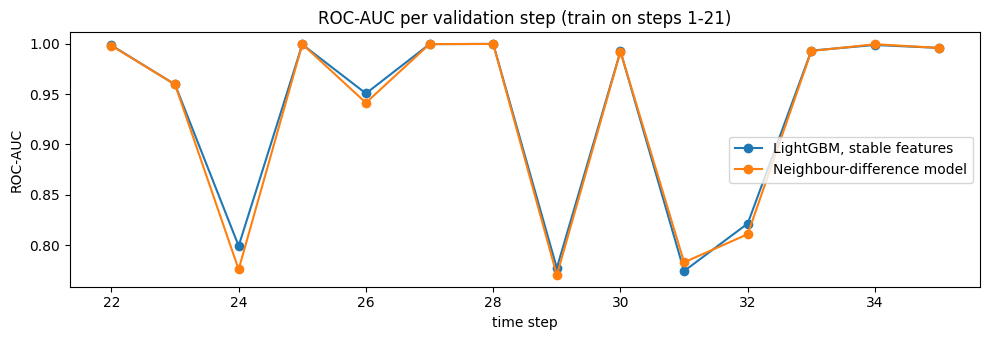

In [197]:
step_auc = pd.DataFrame({
    t: {"LightGBM, stable features": roc_auc_score(val_y[STEP[val_score] == t], p_stable[STEP[val_score] == t]),
        "Neighbour-difference model": roc_auc_score(val_y[STEP[val_score] == t], p_neighbour[STEP[val_score] == t])}
    for t in np.unique(STEP[val_score]) if len(np.unique(val_y[STEP[val_score] == t])) == 2}).T

ax = step_auc.plot(marker="o", figsize=(10, 3.5), title="ROC-AUC per validation step (train on steps 1-21)")
ax.set_xlabel("time step")
ax.set_ylabel("ROC-AUC")
plt.tight_layout()
plt.show()

## 5. Final Neighbour-Difference Model

Trained on all labelled transactions (steps 1-35) and averaged over 20 seeds.

In [198]:
P_NEIGHBOUR = average_over_seeds(LABELLED, TEST_IDX, list(range(42, 62)))  # 20 seeds
print(f"Test predictions: {len(P_NEIGHBOUR):,}; mean {P_NEIGHBOUR.mean():.4f}")

Test predictions: 15,329; mean 0.0485


## 6. Post-Shutdown Adjustment

The neighbour-difference model learned the large illicit campaign from steps 24-32 (big connected clusters of illicit transactions). If illicit activity drops sharply partway through the test period, as happens when a dark market is shut down, the model would still rank connected transactions that only look like the campaign above the median. This section lowers the scores of those transactions:
1. find the test step where the model's scores change, using only the test data
2. label "campaign" transactions in training (illicit transactions in an illicit cluster of 10 or more)
3. train a campaign detector that scores how campaign-like each test transaction is
4. lower the score of connected test transactions from the change point onwards, based on how campaign-like they are

Transactions before the change point are not changed.

### Finding the change point in the test steps

To find whether and where such a drop happens, I look for a change in how suspicious the model finds each test step, using only the test transactions and the model trained on steps 1-35 (no test labels).

For each test step I compute four statistics of the neighbour-difference model's scores: the share of the step's transactions in the top 1%, 2% and 5% of all test scores, and the step's mean score. For each statistic I find the single split of steps 36-49 into two segments that fits best (lowest within-segment sum of squares, at least 2 steps per segment). The cut-off is the step that at least 3 of the 4 statistics agree on. If there is no such agreement, no adjustment is made. Transaction volume is shown for reference but does not vote.


In [199]:
test_step = STEP[TEST_IDX]
test_steps = np.unique(test_step)
score_pct = stats.rankdata(P_NEIGHBOUR) / len(P_NEIGHBOUR)

per_step = pd.DataFrame({
    "share in top 1%": [(score_pct[test_step == t] >= 0.99).mean() for t in test_steps],
    "share in top 2%": [(score_pct[test_step == t] >= 0.98).mean() for t in test_steps],
    "share in top 5%": [(score_pct[test_step == t] >= 0.95).mean() for t in test_steps],
    "mean score": [P_NEIGHBOUR[test_step == t].mean() for t in test_steps],
    "transactions": [(test_step == t).sum() for t in test_steps],
}, index=test_steps)
display(per_step.T.round(4))


def best_split(values, min_len=2):
    x = np.asarray(values, float)
    cost = {int(test_steps[k]): ((x[:k] - x[:k].mean()) ** 2).sum() + ((x[k:] - x[k:].mean()) ** 2).sum()
            for k in range(min_len, len(x) - min_len + 1)}
    return min(cost, key=cost.get)


VOTING = ["share in top 1%", "share in top 2%", "share in top 5%", "mean score"]
splits = pd.Series({c: best_split(per_step[c]) for c in per_step.columns}, name="first step after the change")
display(splits.to_frame())

votes = splits[VOTING].value_counts()
if votes.iloc[0] >= 3:
    SHUTDOWN_STEP = int(votes.index[0])
    print(f"Change point: step {SHUTDOWN_STEP} ({votes.iloc[0]} of {len(VOTING)} score statistics agree)")
else:
    SHUTDOWN_STEP = int(test_steps.max()) + 1  # no agreed change point, so nothing is adjusted
    print("No step that at least 3 of the 4 score statistics agree on, so the adjustment is skipped")


,36,37,38,39,40,41,42,43,44,45,46,47,48,49
share in top 1%,0.0047,0.0141,0.0251,0.0093,0.0165,0.0115,0.0353,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
share in top 2%,0.0111,0.0301,0.0714,0.0220,0.0297,0.0362,0.0539,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
share in top 5%,0.0252,0.0562,0.1376,0.0761,0.0751,0.1007,0.0938,0.0036,0.0220,0.0254,0.0098,0.0059,0.0021,0.0231
mean score,0.0261,0.0536,0.1366,0.0758,0.0709,0.0996,0.0923,0.0050,0.0185,0.0201,0.0095,0.0049,0.0039,0.0166
transactions,1708.0000,498.0000,756.0000,1183.0000,1211.0000,1132.0000,2154.0000,1370.0000,1591.0000,1221.0000,712.0000,846.0000,471.0000,476.0000


,first step after the change
share in top 1%,43
share in top 2%,43
share in top 5%,43
mean score,43
transactions,46


Change point: step 43 (4 of 4 score statistics agree)


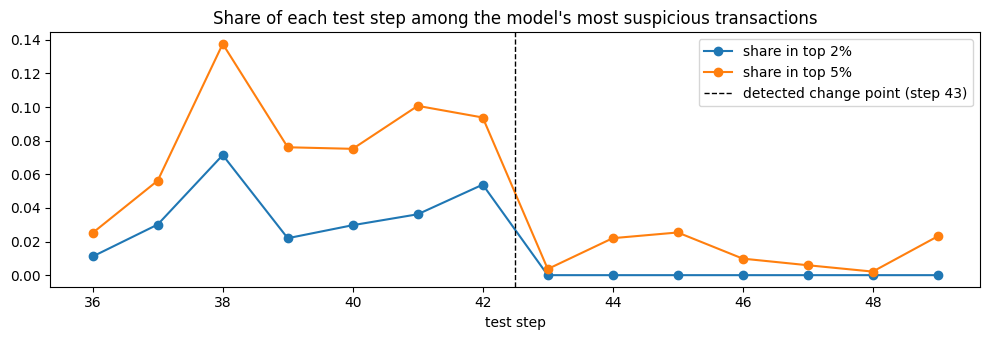

In [200]:
ax = per_step[["share in top 2%", "share in top 5%"]].plot(marker="o", figsize=(10, 3.5),
                                                          title="Share of each test step among the model's most suspicious transactions")
if SHUTDOWN_STEP <= test_steps.max():
    ax.axvline(SHUTDOWN_STEP - 0.5, color="black", ls="--", lw=1, label=f"detected change point (step {SHUTDOWN_STEP})")
ax.legend()
ax.set_xlabel("test step")
plt.tight_layout()
plt.show()


All four score statistics place the change at step 43, the sharpest drop in the test period. From step 43 onwards no transaction is in the top 2% of scores, against 1-7% of each earlier test step, and the mean score falls from 0.092 at step 42 to 0.005. Transaction volume does not show the same break (its best split is at step 46), so it is how suspicious the transactions look that changes, not how many there are.

Submitting the adjustment from different starting steps on the public leaderboard confirmed step 43 as the best choice. Because this was checked on the public leaderboard, part of the gain may not carry over to the private test set.

### Campaign transactions in training

In [201]:
illicit_rows = LABELLED[LABEL[LABELLED] == 1]
n_clusters, cluster_id = connected_components(UND[illicit_rows][:, illicit_rows], directed=False)
cluster_size = np.bincount(cluster_id, minlength=n_clusters)[cluster_id]

CAMPAIGN = np.full(N, np.nan)
CAMPAIGN[LABELLED] = 0.0
CAMPAIGN[illicit_rows[cluster_size >= 10]] = 1.0 

print(f"Campaign transactions: {int(np.nansum(CAMPAIGN))} of {len(illicit_rows):,} illicit")
assert np.nansum(CAMPAIGN) >= 20, "too few campaign transactions to train the detector" 
display(pd.Series(STEP[CAMPAIGN == 1]).value_counts().sort_index().rename("campaign transactions").to_frame().T)

Campaign transactions: 484 of 3,644 illicit


,7,20,21,23,24,26,29,31,32
campaign transactions,11,33,14,10,78,10,183,45,100


### Campaign detector

Same setup as the neighbour-difference model, but the target is campaign vs. all other labelled transactions. The scores are turned into percentiles over the test set (0 = least campaign-like, 1 = most).

In [202]:
P_CAMPAIGN = average_over_seeds(LABELLED, TEST_IDX, list(range(42, 52)), target=CAMPAIGN)  # 10 seeds
CAMPAIGN_PCT = stats.rankdata(P_CAMPAIGN) / len(P_CAMPAIGN)

post_shutdown = test_step >= SHUTDOWN_STEP 
connected_test = CONNECTED[TEST_IDX]
print(f"Post-shutdown test transactions: {post_shutdown.sum():,} ({(post_shutdown & connected_test).sum():,} connected)")

Post-shutdown test transactions: 6,687 (5,205 connected)


### Applying the demotion

For a connected post-shutdown transaction with score percentile r and campaign percentile c:
- w = (c - 0.5) / 0.5, clipped to [0, 1], so only above-median campaign scores count
- new percentile = r * (1 - α * w), with α = 0.75
- the new percentile is mapped back to a score on the neighbour-difference model's scale

α = 0.75 moves the large campaign-like clusters in step 44 that the model ranked highly (around the 82nd–87th percentile) to roughly the median, treating them as uncertain rather than licit (see the table below). α = 1.0 and  α = 0.3 both scored worse on the public leaderboard.

In [203]:
def post_shutdown_adjustment(scores, alpha=0.75, floor=0.5):
    excess = np.clip((CAMPAIGN_PCT - floor) / (1 - floor), 0, 1)
    target = post_shutdown & connected_test
    pct = stats.rankdata(scores) / len(scores)
    new_pct = pct.copy()
    new_pct[target] = pct[target] * (1 - alpha * excess[target])
    adjusted = scores.copy()
    adjusted[target] = np.quantile(scores, np.clip(new_pct[target], 0, 1))
    return adjusted


P_FINAL = post_shutdown_adjustment(P_NEIGHBOUR)

demoted = (stats.rankdata(P_FINAL) - stats.rankdata(P_NEIGHBOUR)) / len(P_NEIGHBOUR) < -0.05
print(f"Transactions demoted by more than 5 percentile points: {demoted.sum():,} (all after step {SHUTDOWN_STEP - 1}: {bool((~demoted | post_shutdown).all())})")
print(f"Order of pre-shutdown transactions unchanged: {stats.spearmanr(P_FINAL[~post_shutdown], P_NEIGHBOUR[~post_shutdown]).correlation:.4f}")

Transactions demoted by more than 5 percentile points: 2,278 (all after step 42: True)
Order of pre-shutdown transactions unchanged: 1.0000


In [204]:
ALPHAS = [0.5, 0.75, 1.0]

def to_pct(scores):
    return stats.rankdata(scores) / len(scores)

m44 = test_step == 44
idx44 = TEST_IDX[m44]
_, comp = connected_components(UND[idx44][:, idx44], directed=False)

df44 = pd.DataFrame({"cluster": comp,
                     "campaign_pct": CAMPAIGN_PCT[m44],
                     "pct_before": to_pct(P_NEIGHBOUR)[m44]})
for a in ALPHAS:
    df44[f"pct_after α={a}"] = to_pct(post_shutdown_adjustment(P_NEIGHBOUR, alpha=a))[m44]

summary = df44.groupby("cluster").mean()
summary.insert(0, "size", df44.groupby("cluster").size())
display(summary[summary["size"] >= 10]
        .sort_values("campaign_pct", ascending=False)
        .head(10).round(3))

# how much each alpha changes overall
overall = {}
for a in ALPHAS:
    shift = to_pct(post_shutdown_adjustment(P_NEIGHBOUR, alpha=a)) - to_pct(P_NEIGHBOUR)
    overall[f"α={a}"] = {
        "demoted > 5 pct points": int((shift < -0.05).sum()),
        "demoted > 20 pct points": int((shift < -0.20).sum()),
        "mean shift (post-shutdown, connected)": shift[post_shutdown & connected_test].mean(),
    }
display(pd.DataFrame(overall).round(3))

,size,campaign_pct,pct_before,pct_after α=0.5,pct_after α=0.75,pct_after α=1.0
cluster,,,,,,
23,11,0.976,0.449,0.252,0.146,0.032
22,12,0.969,0.391,0.222,0.129,0.037
21,21,0.800,0.874,0.665,0.544,0.413
48,10,0.800,0.583,0.452,0.385,0.317
2,13,0.781,0.866,0.677,0.567,0.448
31,32,0.779,0.815,0.630,0.528,0.415
33,10,0.779,0.606,0.461,0.391,0.314
47,10,0.773,0.636,0.493,0.420,0.343
3,163,0.765,0.823,0.634,0.525,0.407


,α=0.5,α=0.75,α=1.0
demoted > 5 pct points,2098.000,2278.000,2348.00
demoted > 20 pct points,810.000,1323.000,1631.00
"mean shift (post-shutdown, connected)",-0.063,-0.096,-0.13


## 7. Submission

In [205]:
submission = pd.DataFrame({"index": df_test["index"].to_numpy(), "target": P_FINAL})
assert submission["target"].notna().all() and submission["index"].is_unique

OUT_DIR = Path("outputs_final")
OUT_DIR.mkdir(exist_ok=True)
submission.to_csv(OUT_DIR / "submission.csv", index=False)
print("Saved", OUT_DIR / "submission.csv")
display(submission.head())

Saved outputs_final\submission.csv


,index,target
0,0,0.000186
1,1,0.001117
2,2,0.000196
3,3,0.000282
4,4,0.000082


## 8. Performance Evaluation

The test labels are hidden, so I evaluate on the labelled training steps, always training on earlier steps and testing on later ones:

| Window | Train steps | Test steps |
| --- | --- | --- |
| Far | 1-21 | 22-35 |
| Expose | 1-24 | 25-35 |
| Late | 1-29 | 30-35 |

Metrics: ROC-AUC, PR-AUC, and accuracy, precision, recall and F1 for the illicit class at a 0.5 threshold.

Models compared: three baselines on all 165 raw features (logistic regression, random forest with 300 trees, and LightGBM), then LightGBM on stable features and the neighbour-difference model. The baselines use median imputation for missing values, except LightGBM, which handles them itself.

### Helper functions

In [206]:
from sklearn.metrics import (accuracy_score, average_precision_score, confusion_matrix, f1_score,
                             precision_recall_curve, precision_score, recall_score, roc_curve)
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

WINDOWS = {"Far": (21, 22, 35), "Expose": (24, 25, 35), "Late": (29, 30, 35)}


def window_rows(name):
    last_train, first_score, last_score = WINDOWS[name]
    train_rows = LABELLED[STEP[LABELLED] <= last_train]
    score_rows = LABELLED[(STEP[LABELLED] >= first_score) & (STEP[LABELLED] <= last_score)]
    return train_rows, score_rows


def build_features(train_rows, score_rows, use_edges=True):
    rows = np.r_[train_rows, score_rows]
    blocks = [("raw", X_ALL)] + ([("edge", EDGE_DIFF)] if use_edges else [])
    parts = []
    for name, B in blocks:
        cols = stable_features(B, train_rows, name)
        parts.append(B[rows][:, cols if len(cols) else np.arange(B.shape[1])])
    X = np.hstack(parts)
    return X[:len(train_rows)], X[len(train_rows):]


def lgb_all_features(train_rows, score_rows, seeds):
    y = LABEL[train_rows].astype(int)
    preds = []
    for s in seeds:
        model = lgb.LGBMClassifier(random_state=s, **LGB_PARAMS)
        model.fit(X_ALL[train_rows], y)
        preds.append(model.predict_proba(X_ALL[score_rows])[:, 1])
    return np.mean(preds, axis=0)


def random_forest(train_rows, score_rows, seed=42):
    X_tr, X_sc = X_ALL[train_rows], X_ALL[score_rows]
    imp = SimpleImputer(strategy="median").fit(X_tr)
    rf = RandomForestClassifier(n_estimators=300, min_samples_leaf=2, n_jobs=4, random_state=seed)
    rf.fit(imp.transform(X_tr), LABEL[train_rows].astype(int))
    return rf.predict_proba(imp.transform(X_sc))[:, 1]


def logistic_regression(train_rows, score_rows):
    X_tr, X_sc = X_ALL[train_rows], X_ALL[score_rows]
    lr = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(max_iter=2000))
    lr.fit(X_tr, LABEL[train_rows].astype(int))
    return lr.predict_proba(X_sc)[:, 1]


def metrics_row(y, p):
    out = {"ROC-AUC": roc_auc_score(y, p), "PR-AUC": average_precision_score(y, p)}
    pred = (p >= 0.5).astype(int)
    out.update({"Accuracy @0.5": accuracy_score(y, pred), "Precision @0.5": precision_score(y, pred, zero_division=0),
                "Recall @0.5": recall_score(y, pred), "F1 @0.5": f1_score(y, pred)})
    return out

### Scoring every model on every window

For the far window I reuse `p_stable` and `p_neighbour` from section 4 since they use the same seeds.

In [207]:
VAL = {}
for w in WINDOWS:
    tr, sc = window_rows(w)
    preds = {}
    preds["Logistic regression"] = logistic_regression(tr, sc)
    preds["Random forest"] = random_forest(tr, sc)
    preds["LightGBM, all features"] = lgb_all_features(tr, sc, [42, 43, 44])
    if w == "Far":
        preds["LightGBM, stable features"], preds["Neighbour-difference model"] = p_stable, p_neighbour
    else:
        preds["LightGBM, stable features"] = average_over_seeds(tr, sc, [42, 43, 44], use_edges=False)
        preds["Neighbour-difference model"] = average_over_seeds(tr, sc, [42, 43, 44], use_edges=True)
    VAL[w] = {"y": LABEL[sc].astype(int), "rows": sc, "preds": preds}
    print(f"{w}: trained on {len(tr):,}, scored {len(sc):,} ({VAL[w]['y'].sum():,} illicit)")

MODELS = list(VAL["Far"]["preds"])

Far: trained on 19,530, scored 11,705 (1,773 illicit)
Expose: trained on 23,606, scored 7,629 (1,425 illicit)
Late: trained on 26,381, scored 4,854 (773 illicit)


### Results for all models and windows

In [208]:
results = pd.DataFrame({(w, m): metrics_row(VAL[w]["y"], VAL[w]["preds"][m])
                        for w in WINDOWS for m in MODELS}).T
results.index.names = ["window", "model"]
display(results.round(4))
results.round(4).to_csv(OUT_DIR / "validation_metrics.csv")

ROC-AUC  PR-AUC  Accuracy @0.5  Precision @0.5  Recall @0.5  F1 @0.5
window model                                                                                           
Far    Logistic regression          0.8280  0.4673         0.8191          0.4396       0.7078   0.5424
       Random forest                0.8187  0.7812         0.9480          0.9770       0.6723   0.7965
       LightGBM, all features       0.8873  0.8055         0.9473          0.9624       0.6785   0.7959
       LightGBM, stable features    0.9091  0.8174         0.9487          0.9666       0.6847   0.8016
       Neighbour-difference model   0.9054  0.8139         0.9494          0.9728       0.6853   0.8041
Expose Logistic regression          0.8863  0.5565         0.8084          0.4917       0.7726   0.6010
       Random forest                0.9950  0.9867         0.9837          0.9909       0.9214   0.9549
       LightGBM, all features       0.9971  0.9894         0.9820          0.9806       0.9221   0.9505
       LightGBM, stable features    0.9968  0.9890         0.9832          0.9836       0.9256   0.9537
       Neighbour-difference model   0.9963  0.9875         0.9809          0.9783       0.9179   0.9471
Late   Logistic regression          0.9285  0.6627         0.8467          0.5116       0.8305   0.6331
       Random forest                0.9954  0.9880         0.9897          0.9852       0.9495   0.9671
       LightGBM, all features       0.9978  0.9905         0.9878          0.9760       0.9470   0.9613
       LightGBM, stable features    0.9976  0.9909         0.9891          0.9787       0.9521   0.9652
       Neighbour-difference model   0.9975  0.9904         0.9889          0.9712       0.9586   0.9648

### Accuracy baseline

Accuracy of a "model" that just predicts licit for every transaction.

In [209]:
baseline = pd.DataFrame({w: {"illicit share": VAL[w]["y"].mean(),
                         "accuracy of 'always licit'": 1 - VAL[w]["y"].mean(),
                         "model accuracy @0.5": results.loc[(w, "Neighbour-difference model"), "Accuracy @0.5"],
                         "model recall @0.5": results.loc[(w, "Neighbour-difference model"), "Recall @0.5"]} for w in WINDOWS}).T
display(baseline.round(3))

,illicit share,accuracy of 'always licit',model accuracy @0.5,model recall @0.5
Far,0.151,0.849,0.949,0.685
Expose,0.187,0.813,0.981,0.918
Late,0.159,0.841,0.989,0.959


### ROC-AUC and F1 by window

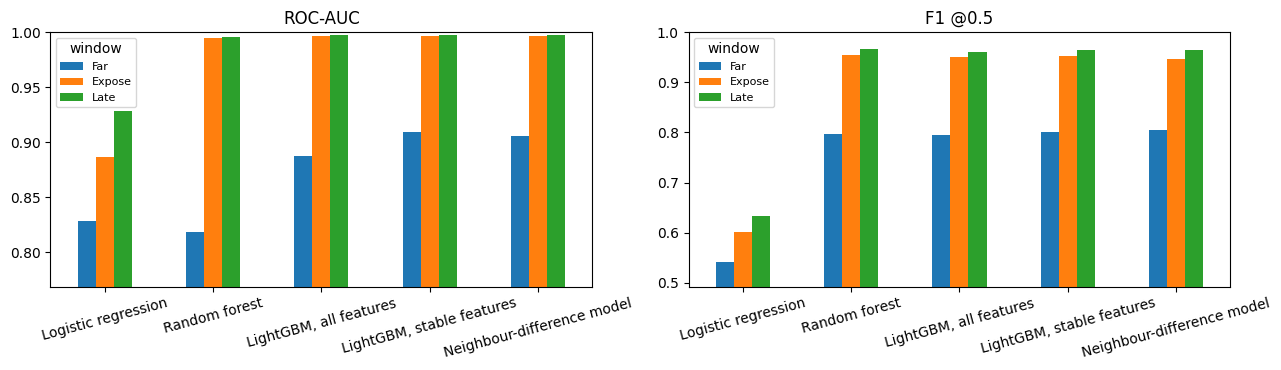

In [210]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
for a, metric in zip(ax, ["ROC-AUC", "F1 @0.5"]):
    results[metric].unstack("window")[list(WINDOWS)].loc[MODELS].plot.bar(ax=a, rot=15)
    a.set_title(metric)
    a.set_xlabel("")
    a.set_ylim(results[metric].min() - 0.05, 1.0)
    a.legend(title="window", fontsize=8)
plt.tight_layout()
plt.show()

### Does the neighbour-difference model differ from LightGBM on stable features?

Transactions in the same step are related, so I resample whole time steps (1000 times) and recompute the ROC-AUC difference between the neighbour-difference model and LightGBM on stable features.

Offline the two models are effectively tied. On the public leaderboard the neighbour-difference model scored higher so i kept it.

In [211]:
def step_block_bootstrap(y, p_new, p_old, steps, n_boot=1000, seed=42):
    rng = np.random.default_rng(seed)
    uniq = np.unique(steps)
    by_step = {t: np.flatnonzero(steps == t) for t in uniq}
    gains = []
    for _ in range(n_boot):
        idx = np.concatenate([by_step[t] for t in rng.choice(uniq, len(uniq), replace=True)])
        if len(np.unique(y[idx])) == 2:
            gains.append(roc_auc_score(y[idx], p_new[idx]) - roc_auc_score(y[idx], p_old[idx]))
    return np.array(gains)


boot = []
for w in WINDOWS:
    v = VAL[w]
    g = step_block_bootstrap(v["y"], v["preds"]["Neighbour-difference model"], v["preds"]["LightGBM, stable features"], STEP[v["rows"]])
    boot.append({"window": w, "ROC-AUC gain": roc_auc_score(v["y"], v["preds"]["Neighbour-difference model"]) - roc_auc_score(v["y"], v["preds"]["LightGBM, stable features"]),
                 "95% CI low": np.percentile(g, 2.5), "95% CI high": np.percentile(g, 97.5),
                 "share of resamples with a gain": (g > 0).mean()})
display(pd.DataFrame(boot).set_index("window").round(4))

,ROC-AUC gain,95% CI low,95% CI high,share of resamples with a gain
window,,,,
Far,-0.0037,-0.0092,0.0006,0.048
Expose,-0.0005,-0.0010,-0.0001,0.007
Late,-0.0001,-0.0006,0.0004,0.353


### ROC and precision-recall curves (far window)

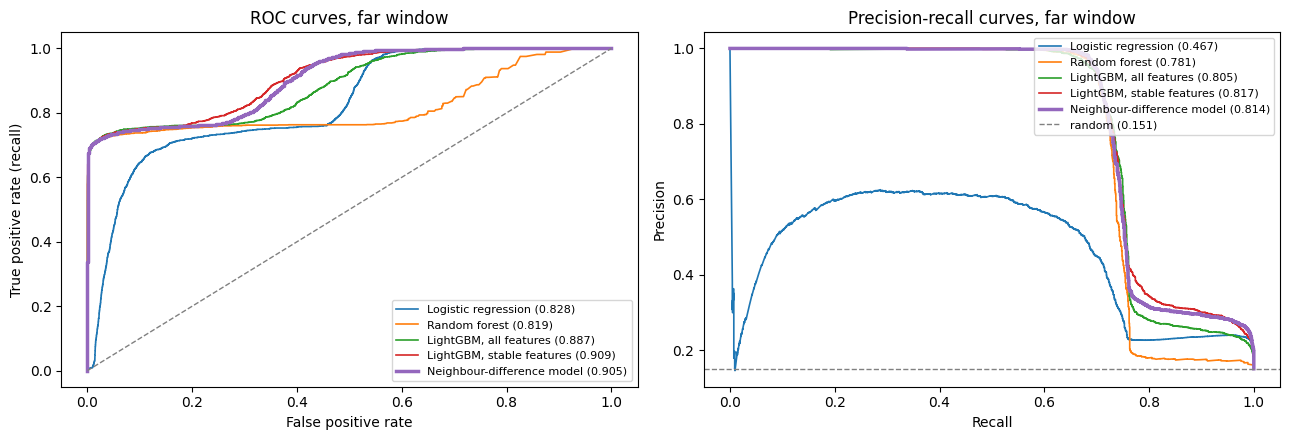

In [212]:
v = VAL["Far"]
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for m in MODELS:
    fpr, tpr, _ = roc_curve(v["y"], v["preds"][m])
    prec, rec, _ = precision_recall_curve(v["y"], v["preds"][m])
    lw = 2.5 if m == "Neighbour-difference model" else 1.2
    ax[0].plot(fpr, tpr, lw=lw, label=f"{m} ({roc_auc_score(v['y'], v['preds'][m]):.3f})")
    ax[1].plot(rec, prec, lw=lw, label=f"{m} ({average_precision_score(v['y'], v['preds'][m]):.3f})")
ax[0].plot([0, 1], [0, 1], color="grey", ls="--", lw=1)
ax[0].set(xlabel="False positive rate", ylabel="True positive rate (recall)", title="ROC curves, far window")
ax[1].axhline(v["y"].mean(), color="grey", ls="--", lw=1, label=f"random ({v['y'].mean():.3f})")
ax[1].set(xlabel="Recall", ylabel="Precision", title="Precision-recall curves, far window")
for a in ax:
    a.legend(fontsize=8, loc="lower right" if a is ax[0] else "upper right")
plt.tight_layout()
plt.show()

### Confusion matrix for the neighbour-difference model (far window)

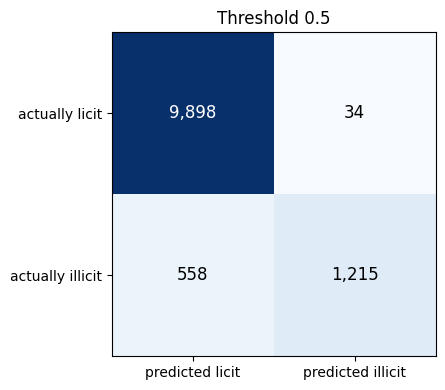

In [213]:
p = v["preds"]["Neighbour-difference model"]
cm = confusion_matrix(v["y"], (p >= 0.5).astype(int))

fig, ax = plt.subplots(figsize=(5, 4))
ax.imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{cm[i, j]:,}", ha="center", va="center", fontsize=12,
                color="white" if cm[i, j] > cm.max() / 2 else "black")
ax.set_xticks([0, 1])
ax.set_xticklabels(["predicted licit", "predicted illicit"])
ax.set_yticks([0, 1])
ax.set_yticklabels(["actually licit", "actually illicit"])
ax.set_title("Threshold 0.5")
plt.tight_layout()
plt.show()

### Precision, recall and F1 vs. threshold (neighbour-difference model, far window)

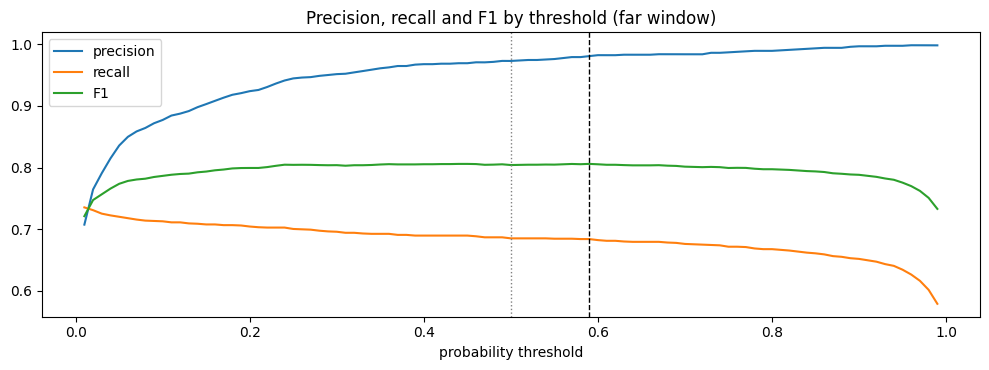

Best F1 0.806 at threshold 0.59 (precision 0.981, recall 0.684)
At 0.5: precision 0.973, recall 0.685


In [214]:
thr_grid = np.linspace(0.01, 0.99, 99)
p = v["preds"]["Neighbour-difference model"]
curve = pd.DataFrame({"precision": [precision_score(v["y"], p >= t, zero_division=0) for t in thr_grid],
                      "recall": [recall_score(v["y"], p >= t) for t in thr_grid],
                      "F1": [f1_score(v["y"], p >= t) for t in thr_grid]}, index=thr_grid)
best_t = curve["F1"].idxmax()

ax = curve.plot(figsize=(10, 3.8), title="Precision, recall and F1 by threshold (far window)")
ax.axvline(0.5, color="grey", ls=":", lw=1)
ax.axvline(best_t, color="black", ls="--", lw=1)
ax.set_xlabel("probability threshold")
plt.tight_layout()
plt.show()
print(f"Best F1 {curve['F1'].max():.3f} at threshold {best_t:.2f} (precision {curve.loc[best_t, 'precision']:.3f}, recall {curve.loc[best_t, 'recall']:.3f})")
t05 = thr_grid[np.argmin(np.abs(thr_grid - 0.5))]
print(f"At 0.5: precision {curve.loc[t05, 'precision']:.3f}, recall {curve.loc[t05, 'recall']:.3f}")

### Errors by time step (far window)

,22,23,24,25,26,27,28,29,30,31,32,33,34,35
illicit,158.000,53.000,137.000,118.000,96.000,24.000,85.0,329.000,83.000,106.000,342.000,23.000,37.000,182.000
caught,146.000,32.000,43.000,113.000,72.000,23.000,85.0,117.000,74.000,53.000,233.000,18.000,33.000,173.000
missed,12.000,21.000,94.000,5.000,24.000,1.000,0.0,212.000,9.000,53.000,109.000,5.000,4.000,9.000
false alarms,4.000,2.000,1.000,1.000,4.000,0.000,1.0,2.000,2.000,9.000,1.000,0.000,0.000,7.000
recall,0.924,0.604,0.314,0.958,0.750,0.958,1.0,0.356,0.892,0.500,0.681,0.783,0.892,0.951
ROC-AUC,0.998,0.960,0.776,1.000,0.941,1.000,1.0,0.770,0.992,0.783,0.811,0.993,1.000,0.996


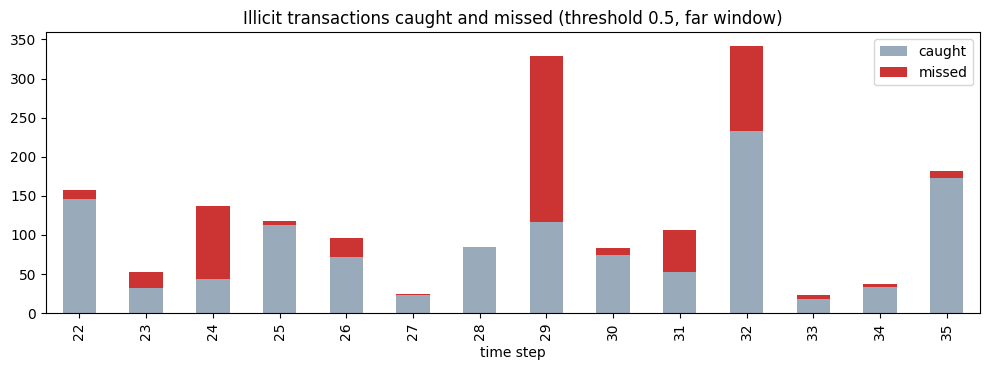

In [215]:
steps_v = STEP[v["rows"]]
flag = p >= 0.5
by_step = pd.DataFrame({
    "illicit": pd.Series(v["y"]).groupby(steps_v).sum(),
    "caught": pd.Series((v["y"] == 1) & flag).groupby(steps_v).sum(),
    "missed": pd.Series((v["y"] == 1) & ~flag).groupby(steps_v).sum(),
    "false alarms": pd.Series((v["y"] == 0) & flag).groupby(steps_v).sum(),
})
by_step["recall"] = by_step["caught"] / by_step["illicit"].replace(0, np.nan)
by_step["ROC-AUC"] = [roc_auc_score(v["y"][steps_v == t], p[steps_v == t])
                      if len(np.unique(v["y"][steps_v == t])) == 2 else np.nan for t in by_step.index]
display(by_step.T.round(3))

ax = by_step[["caught", "missed"]].plot.bar(stacked=True, figsize=(10, 3.8), color=["#9ab", "#c33"],
                                             title="Illicit transactions caught and missed (threshold 0.5, far window)")
ax.set_xlabel("time step")
plt.tight_layout()
plt.show()

### Caught vs. missed illicit transactions

In [216]:
ill = v["y"] == 1
neigh_illicit = np.full(N, np.nan)
lab_mask = np.isfinite(LABEL)
deg_lab = np.asarray(UND[:, lab_mask].sum(axis=1)).ravel()
ill_neigh = np.asarray(UND @ np.where(LABEL == 1, 1.0, 0.0)).ravel()
neigh_illicit[deg_lab > 0] = ill_neigh[deg_lab > 0] / deg_lab[deg_lab > 0]

rows_ill = v["rows"][ill]
caught_mask = flag[ill]
profile = pd.DataFrame({
    group: {"transactions": int(mask.sum()),
            "in a campaign cluster (10+ illicit)": np.mean(CAMPAIGN[rows_ill[mask]] == 1),
            "connected to another transaction": CONNECTED[rows_ill[mask]].mean(),
            "illicit share of labelled neighbours": np.nanmean(neigh_illicit[rows_ill[mask]]),
            "mean model score": p[ill][mask].mean()}
    for group, mask in [("caught", caught_mask), ("missed", ~caught_mask)]}).T
display(profile.round(3))

,transactions,in a campaign cluster (10+ illicit),connected to another transaction,illicit share of labelled neighbours,mean model score
caught,1215.0,0.006,0.427,0.461,0.984
missed,558.0,0.751,0.964,0.920,0.028


### Do all models miss the same transactions?

In [217]:
missed = {m: ill & (v["preds"][m] < 0.5) for m in MODELS}
missed_by_all = np.logical_and.reduce(list(missed.values()))
overlap = pd.DataFrame({m: {"missed illicit": int(missed[m].sum()),
                            "also missed by every other model": int((missed[m] & missed_by_all).sum()),
                            "share": (missed[m] & missed_by_all).sum() / max(missed[m].sum(), 1)} for m in MODELS}).T
display(overlap.round(3))
print(f"Illicit transactions missed by all {len(MODELS)} models: {missed_by_all.sum():,} of {ill.sum():,}")

,missed illicit,also missed by every other model,share
Logistic regression,518.0,470.0,0.907
Random forest,581.0,470.0,0.809
"LightGBM, all features",570.0,470.0,0.825
"LightGBM, stable features",559.0,470.0,0.841
Neighbour-difference model,558.0,470.0,0.842


Illicit transactions missed by all 5 models: 470 of 1,773


### Feature importance

The neighbour-difference model is refitted once on all labelled transactions (one seed) to get the gain importance of each feature.

,features,share of total gain
edge difference,162,0.106
raw feature,96,0.894


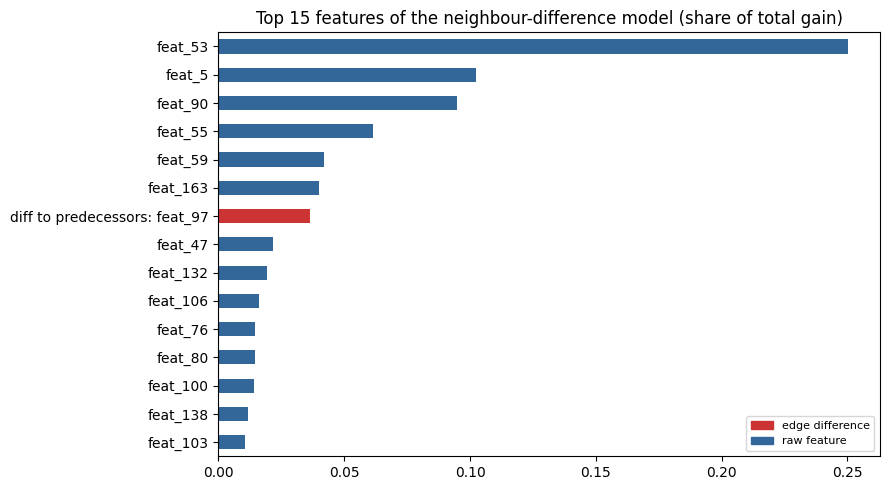

In [218]:
raw_cols = stable_features(X_ALL, LABELLED, "raw")
edge_cols = stable_features(EDGE_DIFF, LABELLED, "edge")
N_RAW = X_ALL.shape[1]
edge_names = [f"diff to predecessors: {feature_cols[j]}" if j < N_RAW else f"diff to successors: {feature_cols[j - N_RAW]}"
              for j in range(2 * N_RAW)]
names = [feature_cols[j] for j in raw_cols] + [edge_names[j] for j in edge_cols]

X_tr, _ = build_features(LABELLED, LABELLED[:1])
imp_model = lgb.LGBMClassifier(random_state=42, **LGB_PARAMS).fit(X_tr, LABEL[LABELLED].astype(int))
importance = pd.Series(imp_model.booster_.feature_importance("gain"), index=names)
importance = importance / importance.sum()

kind = pd.Series(np.where(importance.index.str.startswith("diff"), "edge difference", "raw feature"), index=importance.index)
display(importance.groupby(kind).agg(["count", "sum"]).rename(columns={"count": "features", "sum": "share of total gain"}).round(3))

top = importance.sort_values().tail(15)
colors = {"edge difference": "#c33", "raw feature": "#369"}
ax = top.plot.barh(figsize=(9, 5), color=[colors[kind[n]] for n in top.index], title="Top 15 features of the neighbour-difference model (share of total gain)")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in colors.values()], labels=list(colors), fontsize=8)
plt.tight_layout()
plt.show()